In [28]:
# load and inspect data

import pandas as pd
import numpy as np

df = pd.read_csv("Econom_Cities_data.csv", sep=";", decimal=",")
print(df.shape)          # (48, 4)
print(df.head())
print(df.dtypes)

(48, 4)
        City  Work  Price  Salary
0  Amsterdam  1714   65.6    49.0
1     Athens  1792   53.8    30.4
2     Bogota  2152   37.9    11.5
3     Bombay  2052   30.3     5.3
4   Brussels  1708   73.8    50.5
City          str
Work        int64
Price     float64
Salary    float64
dtype: object


In [29]:
# Handle the missing value

df = df.replace(-9999, np.nan)
print(df.isna().sum())
# Work 2
# Price 0
# Salary 2

City      0
Work      2
Price     0
Salary    2
dtype: int64


In [30]:
# Data dropping 
df_clean = df.dropna().reset_index(drop=True)
print(df_clean.shape) # (46, 4)

(46, 4)


In [31]:
# Prepare features for clustering
# Select nnumeric variables "Work", "Price", "Salary
# City is label

features = ["Work", "Price", "Salary"]
X = df_clean[features].values

In [32]:
# Standardize (z-scores)

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [33]:
# Factor analysis to reduce redundacy for "Price" and "Salary"

from sklearn.decomposition import FactorAnalysis

fa = FactorAnalysis(n_components=2, random_state=42)
X_fa = fa.fit_transform(X_scaled)
print(fa.components_)

[[-0.51249509  0.89464291  0.8965747 ]
 [ 0.2276991   0.02644779  0.01147057]]


In [34]:
# Find the distance Matrix and linkage
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist

In [35]:
# Euclidean distances between cities
D = pdist(X_scaled, metric="euclidean")

In [36]:
# Ward linkage minimizes within-cluster variance — good default
Z = linkage(D, method="ward")

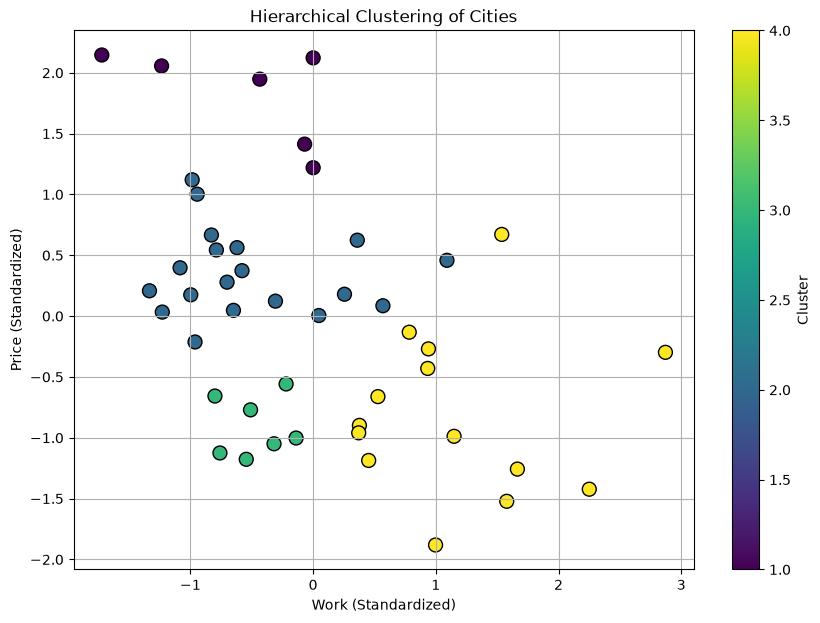

In [60]:
# pathcollection

plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=clusters,
    cmap='viridis',
    s=100,
    edgecolors='black'
)

plt.xlabel('Work (Standardized)')
plt.ylabel('Price (Standardized)')
plt.title('Hierarchical Clustering of Cities')

plt.colorbar(scatter, label='Cluster')
plt.grid(True)
plt.show()

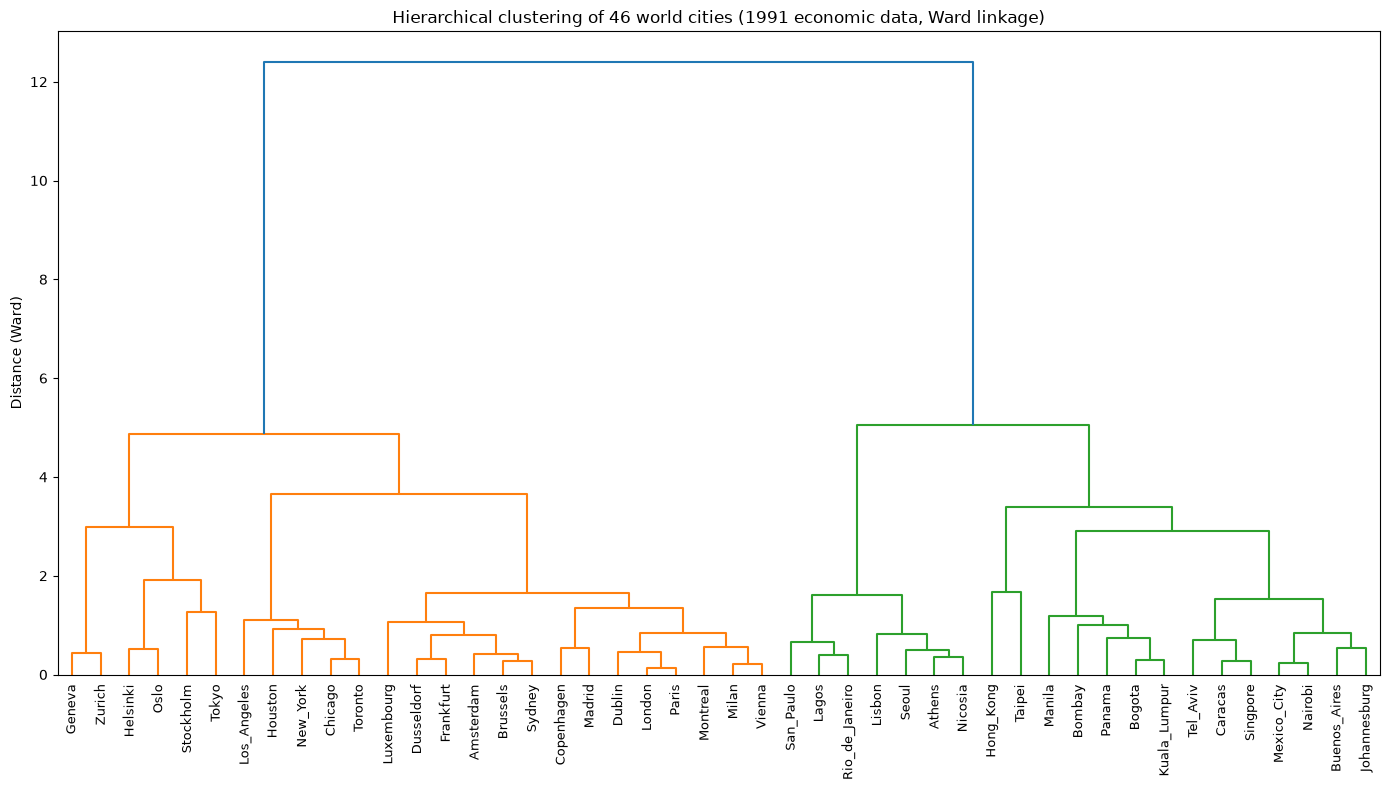

In [37]:
# visulize the dendrogram
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 8))
dendrogram(
    Z,
    labels=df_clean["City"].values,
    leaf_rotation=90,
    leaf_font_size=9,
)
plt.title("Hierarchical clustering of 46 world cities (1991 economic data, Ward linkage)")
plt.ylabel("Distance (Ward)")
plt.tight_layout()
plt.show()

In [57]:
# Cut the tree into K clusters

# Option A: choose number of clusters
k = 4
clusters = fcluster(Z, t=k, criterion="maxclust")

# Option B: choose a distance threshold
clusters = fcluster(Z, t=4.0, criterion="distance")

df_clean["Cluster"] = clusters
print(df_clean.sort_values("Cluster")[["City", "Cluster", "Work", "Price", "Salary"]])

              City  Cluster    Work  Price  Salary
12          Geneva        1  1880.0   95.9    90.3
13        Helsinki        1  1667.0  113.6    66.6
31            Oslo        1  1583.0  115.5    63.7
38       Stockholm        1  1805.0  111.3    39.2
42           Tokyo        1  1880.0  115.0    68.0
45          Zurich        1  1868.0  100.0   100.0
9           Dublin        2  1759.0   76.0    41.4
0        Amsterdam        2  1714.0   65.6    49.0
15         Houston        2  1978.0   71.9    46.3
10      Dusseldorf        2  1693.0   78.5    60.2
29        New_York        2  1942.0   83.3    65.8
26           Milan        2  1773.0   82.0    53.3
22      Luxembourg        2  1768.0   71.1    71.1
8       Copenhagen        2  1717.0   91.3    62.9
7          Chicago        2  1924.0   73.9    61.9
4         Brussels        2  1708.0   73.8    50.5
27        Montreal        2  1827.0   72.7    56.3
20          London        2  1737.0   84.2    46.2
44          Vienna        2  17

In [39]:
# Profile the cluster "Interpretation"

profile = df_clean.groupby("Cluster")[features].mean().round(1)
profile["n_cities"] = df_clean.groupby("Cluster").size()
print(profile)
print(df_clean.groupby("Cluster")["City"].apply(list))

           Work  Price  Salary  n_cities
Cluster                                 
1        1780.5  108.6    71.3         6
2        1792.0   77.5    55.2        19
3        1798.9   50.9    19.2         7
4        2082.4   53.1    14.9        14
Cluster
1    [Geneva, Helsinki, Oslo, Stockholm, Tokyo, Zur...
2    [Amsterdam, Brussels, Chicago, Copenhagen, Dub...
3    [Athens, Lagos, Lisbon, Nicosia, Rio_de_Janeir...
4    [Bogota, Bombay, Buenos_Aires, Caracas, Hong_K...
Name: City, dtype: object


In [40]:
# Validate the choice of K
from scipy.cluster.hierarchy import cophenet
from sklearn.metrics import silhouette_score

# Cophenetic correlation — how well the dendrogram preserves pairwise distances
c, _ = cophenet(Z, D)
print("Cophenetic correlation:", round(c, 3)) # ~0.7–0.8 is good

# Silhouette for a few k values
for k in range(2, 7):
    lab = fcluster(Z, t=k, criterion="maxclust")
    print(k, round(silhouette_score(X_scaled, lab), 3))

Cophenetic correlation: 0.703
2 0.47
3 0.361
4 0.355
5 0.348
6 0.366
